[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch08_rnn_lstm.ipynb)

# 8장 순환 신경망 — RNN과 LSTM · 실습 노트북
『보고, 읽고, 설명하는 딥러닝 — Colab에서 직접 만들며 배우는 딥러닝 응용』

1. 시계열을 학습 샘플로 바꾸기 (`make_sample`)
2. SimpleRNN의 입출력 모양과 파라미터 수
3. 실습 ①: 사인파 예측 (8.6절)
4. 실습 ②: LSTM으로 주가 예측 (8.9절)
5. 전날 값을 그대로 쓰는 기준선과 비교 (8.10절)

CPU 런타임에서 실습 예시 답안까지 모두 실행하면 20분쯤 걸립니다.
> 주가 예측은 순환 신경망을 연습하기 위한 예제이며, 투자 판단에 쓸 수 있는 도구가 아닙니다.

## 1. 시계열을 학습 샘플로 바꾸기

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Input

tf.keras.utils.set_random_seed(42)   # 실행할 때마다 같은 결과가 나오도록 시드 고정

def make_sample(data, window):
    train = []                                  # 공백 리스트 생성
    target = []
    for i in range(len(data)-window):           # 데이터의 길이만큼 반복
        train.append(data[i:i+window])          # i부터 (i+window-1) 까지를 저장
        target.append(data[i+window])           # (i+window) 번째 요소는 정답
    return np.array(train), np.array(target)    # 파이썬 리스트를 넘파이로 변환

윈도우 크기 3으로 짧은 수열을 잘라 보면 어떤 샘플과 정답이 만들어지는지 알 수 있습니다.

In [2]:
data = [16, 8, 32, 9, 23, 11, 19]
X, y = make_sample(data, 3)
for xi, yi in zip(X, y):
    print(xi, '->', yi)

[16  8 32] -> 9
[ 8 32  9] -> 23
[32  9 23] -> 11
[ 9 23 11] -> 19


## 2. SimpleRNN의 입출력 모양과 파라미터 수

In [3]:
# 입력: 타임스텝 2, 시점마다 특성 3개 / 은닉 상태 크기 4
model = Sequential([Input(shape=(2, 3)), SimpleRNN(4)])
model.summary()
print('직접 계산:', 4*4 + 3*4 + 4)   # 은닉→은닉 + 입력→은닉 + 편향

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 4)              │            32 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32 (128.00 B)

 Trainable params: 32 (128.00 B)

 Non-trainable params: 0 (0.00 B)

직접 계산: 32


In [4]:
# 타임스텝을 100으로 늘려도 파라미터 수는 같다 (모든 시점이 같은 가중치를 공유)
model = Sequential([Input(shape=(100, 3)), SimpleRNN(4)])
print(model.count_params())

32


In [5]:
# return_sequences: 마지막 시점의 은닉 상태만 내보낼지, 모든 시점의 은닉 상태를 내보낼지
x = np.random.rand(1, 5, 3).astype('float32')     # 배치 1, 타임스텝 5, 특성 3
print(SimpleRNN(4)(x).shape)
print(SimpleRNN(4, return_sequences=True)(x).shape)

(1, 4)
(1, 5, 4)


## 3. 실습 ①: 사인파 예측

In [6]:
seq_data = []
for i in np.arange(0, 1000):
    seq_data += [[np.sin( np.pi * i* 0.01 )]]
X, y = make_sample(seq_data, 10)        # 윈도우 크기=10
print(X.shape, y.shape)

(990, 10, 1) (990, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


마지막 손실: 0.0008125859312713146


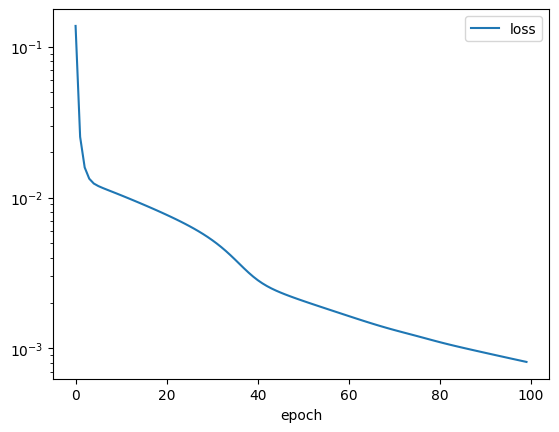

In [7]:
model = Sequential()
model.add(SimpleRNN(10, activation='tanh', input_shape=(10,1)))
model.add(Dense(1, activation='tanh'))
model.compile(optimizer='adam', loss='mse')

history = model.fit(X, y, epochs=100, verbose=0)
print('마지막 손실:', history.history['loss'][-1])
plt.plot(history.history['loss'], label="loss")
plt.yscale('log'); plt.xlabel('epoch'); plt.legend()
plt.show()

코사인파 MSE: 0.0007683023851216748


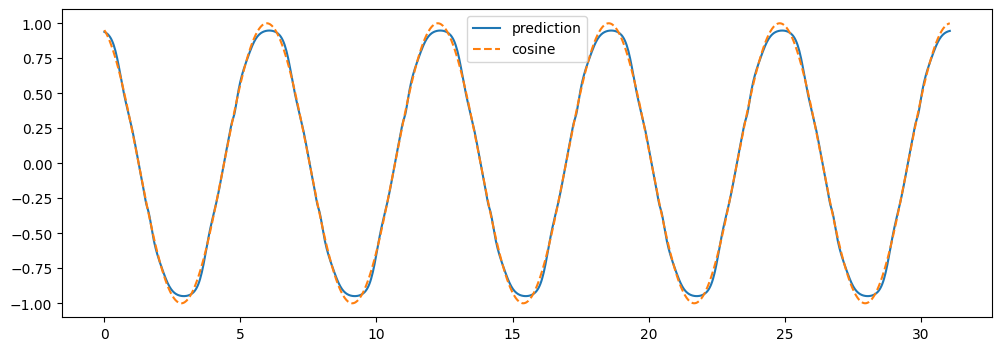

In [8]:
seq_data = []
for i in np.arange(0, 1000):            # 테스트 샘플 생성
    seq_data += [[np.cos( np.pi * i* 0.01 )]]
X, y = make_sample(seq_data, 10)        # 윈도우 크기=10

y_pred = model.predict(X, verbose=0)    # 테스트 예측값
print('코사인파 MSE:', np.mean((y_pred - y)**2))
plt.figure(figsize=(12, 4))
plt.plot(np.pi * np.arange(0, 990)*0.01, y_pred, label='prediction')
plt.plot(np.pi * np.arange(0, 990)*0.01, y, '--', label='cosine')
plt.legend()
plt.show()

## 4. 실습 ②: LSTM으로 주가 예측

In [9]:
!pip install -q finance-datareader

In [10]:
import FinanceDataReader as fdr
from sklearn.preprocessing import MinMaxScaler

# 삼성전자(005930) 2016년부터 — 책과 같은 결과를 보려고 끝 날짜를 정해 둔다
samsung = fdr.DataReader('005930', '2016', '2026-09-30')
print(samsung)
# 거래가 없던 날처럼 시가가 0으로 기록된 행을 뺀다
print('시가가 0인 날:', (samsung['Open'] == 0).sum())
samsung = samsung[samsung['Open'] != 0]

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-09-22  283000  283500  271500  277500  18157410  0.009091
2026-09-23  284500  286500  281000  286500  20864376  0.032432
2026-09-28  284500  285500  268500  270000  21346064 -0.057592
2026-09-29  266000  276000  266000  275000  15963864  0.018519
2026-09-30  274500  276000  267500  269500  16477580 -0.020000

[2634 rows x 6 columns]
시가가 0인 날: 3


In [11]:
openValues = samsung[['Open']]

scaler = MinMaxScaler(feature_range = (0, 1))
scaled = scaler.fit_transform(openValues)

TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]
print(len(train_data), len(test_data))

2431 200


In [12]:
X_train, y_train = make_sample(train_data, 30)
print(X_train.shape, y_train.shape)

(2401, 30, 1) (2401, 1)


In [13]:
model = Sequential()
model.add(LSTM(16, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))

model.compile(optimizer = 'adam', loss = 'mean_squared_error')
model.fit(X_train, y_train, epochs = 100, batch_size = 16, verbose = 0)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,509 (13.71 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,340 (9.14 KB)

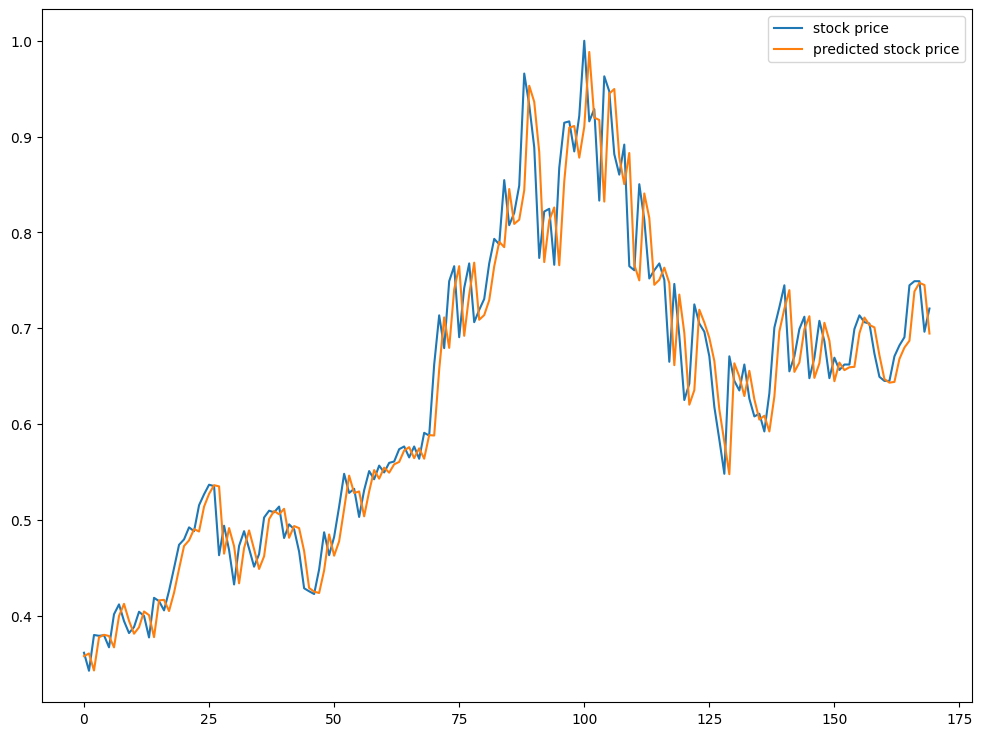

In [14]:
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test, verbose = 0)

plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()

## 5. 전날 값을 그대로 쓰는 기준선과 비교
그래프가 잘 맞아 보여도, 모델 없이 "내일 시가 = 오늘 시가"라고 답하는 것보다 나은지 확인해야 합니다.
비교를 쉽게 하려고 정규화를 되돌려 원 단위로 오차를 잽니다.

In [15]:
to_won = lambda v: scaler.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()
real = to_won(y_test)
lstm = to_won(pred)
naive = to_won(X_test[:, -1, 0])          # 윈도우의 마지막 값 = 전날 시가

print('학습 구간 시가:', int(openValues.Open[:-TEST_SIZE].min()), '~', int(openValues.Open[:-TEST_SIZE].max()), '원')
print('테스트 구간 시가:', int(openValues.Open[-TEST_SIZE:].min()), '~', int(openValues.Open[-TEST_SIZE:].max()), '원')

rmse = lambda a, b: np.sqrt(np.mean((a - b)**2))
print(f'LSTM   RMSE: {rmse(real, lstm):,.0f}원')
print(f'기준선 RMSE: {rmse(real, naive):,.0f}원')

학습 구간 시가: 21760 ~ 111800 원
테스트 구간 시가: 103500 ~ 372500 원
LSTM   RMSE: 14,470원
기준선 RMSE: 14,381원


같은 날끼리 상관계수   : 0.9655
예측을 하루 당긴 상관계수: 0.9998


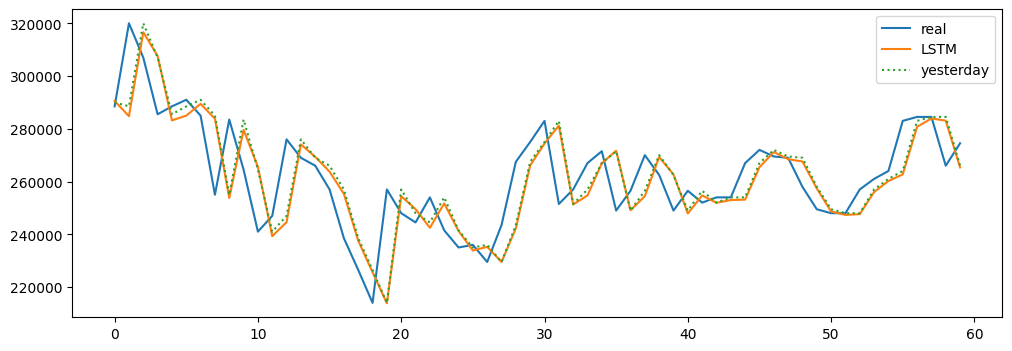

In [16]:
# 예측선을 하루 앞으로 당기면 실제선과 거의 겹친다 → 예측이 하루 늦게 따라간다
corr = lambda a, b: np.corrcoef(a, b)[0, 1]
print('같은 날끼리 상관계수   :', round(corr(real, lstm), 4))
print('예측을 하루 당긴 상관계수:', round(corr(real[:-1], lstm[1:]), 4))

plt.figure(figsize=(12, 4))
plt.plot(real[-60:], label='real')
plt.plot(lstm[-60:], label='LSTM')
plt.plot(naive[-60:], ':', label='yesterday')
plt.legend(); plt.show()

In [17]:
# 오를지 내릴지(방향)를 맞혔는가
up_real = np.sign(real - naive)     # 실제로 전날보다 올랐으면 +1, 내렸으면 -1
up_lstm = np.sign(lstm - naive)     # LSTM이 전날보다 오른다고 했으면 +1
m = up_real != 0                    # 시가가 전날과 같은 날은 뺀다
print(f'방향 적중률(LSTM)       : {(up_real[m] == up_lstm[m]).mean():.1%}')
print(f'방향 적중률(항상 오른다): {(up_real[m] > 0).mean():.1%}')
print(f'실제 시가의 하루 변동 평균      : {np.abs(real - naive).mean():,.0f}원')
print(f'LSTM 예측이 전날 값에서 움직인 폭: {np.abs(lstm - naive).mean():,.0f}원')

방향 적중률(LSTM)       : 44.3%
방향 적중률(항상 오른다): 54.5%
실제 시가의 하루 변동 평균      : 10,546원
LSTM 예측이 전날 값에서 움직인 폭: 1,071원


## 실습
1. **순환 층 바꾸기**: 주가 예측 모델의 `LSTM(16)`을 `SimpleRNN(16)`으로 바꿔 학습하고, 테스트 RMSE를 LSTM·기준선과 비교해 보세요.
2. **윈도우 크기**: `make_sample`의 윈도우를 5, 30, 60으로 바꿔 LSTM의 테스트 RMSE를 비교해 보세요.

먼저 직접 해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [18]:
# 직접 작성해 보세요


### 예시 답안

In [19]:
# 1. 순환 층 바꾸기
def fit_eval(layer, window=30):
    tf.keras.utils.set_random_seed(42)
    Xtr, ytr = make_sample(train_data, window)
    Xte, yte = make_sample(test_data, window)
    m = Sequential([Input(shape=(window, 1)), layer, Dense(1)])
    m.compile(optimizer='adam', loss='mean_squared_error')
    m.fit(Xtr, ytr, epochs=100, batch_size=16, verbose=0)
    p = m.predict(Xte, verbose=0)
    return rmse(to_won(yte), to_won(p)), rmse(to_won(yte), to_won(Xte[:, -1, 0]))

for name, layer in [('SimpleRNN', SimpleRNN(16)), ('LSTM', LSTM(16))]:
    r, b = fit_eval(layer)
    print(f'{name:>9}: {r:,.0f}원  (기준선 {b:,.0f}원)')

SimpleRNN: 19,410원  (기준선 14,381원)


     LSTM: 14,478원  (기준선 14,381원)


In [20]:
# 2. 윈도우 크기
for w in [5, 30, 60]:
    r, b = fit_eval(LSTM(16), window=w)
    print(f'윈도우 {w:>2}: {r:,.0f}원  (기준선 {b:,.0f}원)')

윈도우  5: 13,866원  (기준선 13,518원)
윈도우 30: 15,010원  (기준선 14,381원)
윈도우 60: 16,529원  (기준선 15,402원)
